In [8]:
import pandas as pd
df = pd.read_csv('SouthPark_Episodes.csv')

In [9]:
df.head()

,Title,Air Date,Code,#,Description,Season,Episode
0,Cartman Gets an Anal Probe,"August 13, 1997",101,1,"While the boys are waiting for the school bus,...",1,1
1,Weight Gain 4000,"August 20, 1997",102,2,When Cartman's environmental essay wins a nati...,1,2
2,Volcano,"August 27, 1997",103,3,A weekend trip to experience the finer points ...,1,3
3,Big Gay Al's Big Gay Boat Ride,"September 3, 1997",104,4,"When Stan discovers his new dog Sparky is gay,...",1,4
4,An Elephant Makes Love to a Pig,"September 10, 1997",105,5,"Kyle's mom won't let him keep his new pet, an ...",1,5


In [10]:
df2 = pd.read_csv('SouthPark_Lines.csv')
df2.head()

,Title,Character,Line
0,Cartman Gets an Anal Probe,Scene Description,At the bus stop.
1,Cartman Gets an Anal Probe,The Boys,"School days, school days, teacher's golden ru..."
2,Cartman Gets an Anal Probe,Kyle Broflovski,"Ah, damn it! My little brother's trying to fol..."
3,Cartman Gets an Anal Probe,Ike Broflovski,Eat banana.
4,Cartman Gets an Anal Probe,Kyle,"Ike, you can't come to school with me. [Ike Ch..."


In [13]:
df2['Character'].value_counts().head(10)

Character
Cartman              11307
Scene Description    11116
Stan                  8364
Kyle                  7902
Randy                 3493
Butters               3061
Mr. Garrison          1220
Sharon                1051
Kenny                 1007
Chef                   966
Name: count, dtype: int64

<Axes: xlabel='Character'>

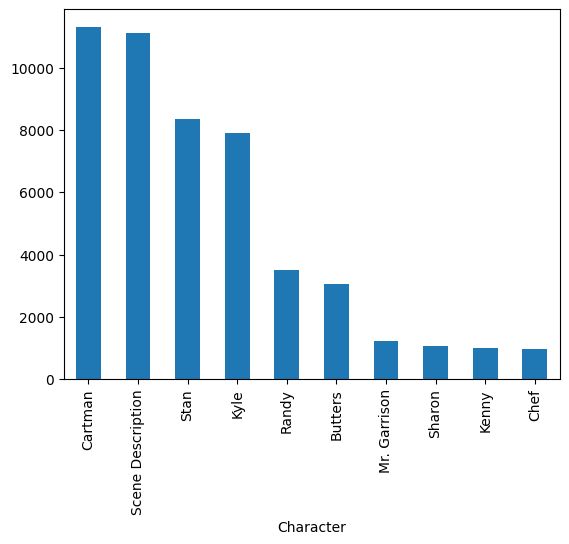

In [14]:
df2['Character'].value_counts().head(10).plot(kind='bar')

<Axes: >

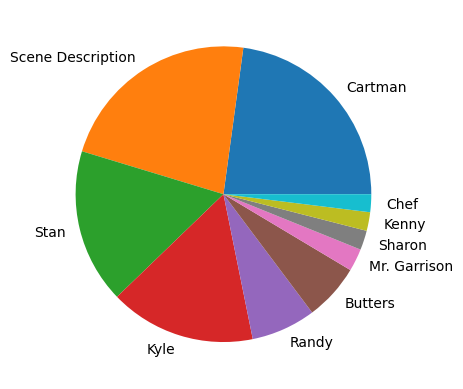

In [16]:
df2['Character'].value_counts().head(10).plot(kind='pie')

In [18]:
df2_no_scene = df2[df2['Character'] != 'Scene Description']
df2_no_scene['Character'].value_counts().head(10)

Character
Cartman         11307
Stan             8364
Kyle             7902
Randy            3493
Butters          3061
Mr. Garrison     1220
Sharon           1051
Kenny            1007
Chef              966
Gerald            965
Name: count, dtype: int64

In [21]:
df_clean = df2[df2['Character'] != 'Scene Description']

In [29]:
cartman_lines = df_clean[df_clean['Character'] == 'Cartman']['Line']
all_words = ' '.join(cartman_lines.fillna('').astype(str)).lower().split()

from collections import Counter
word_counts = Counter(all_words)
print(word_counts.most_common(15))

[('the', 7559), ('and', 4862), ('to', 4745), ('you', 4576), ('a', 3962), ('i', 3820), ('of', 2233), ('is', 1997), ('in', 1741), ('his', 1635), ('it', 1493), ('that', 1447), ('we', 1438), ('on', 1426), ('my', 1417)]


In [30]:
stop_words = {'the', 'and', 'to', 'a', 'of', 'i', 'you', 'is', 'in', 'his', 'it', 'that', 'we', 'on', 'my', 'this', 'for', 'me', 'he', 'your', 'was', 'have', 'with', 'be', 'what', 'are', 'but', 'not', 'so', 'do'}
clean_words = [word for word in all_words if word not in stop_words]
clean_word_counts = Counter(clean_words)
print(clean_word_counts.most_common(15))

[("i'm", 1235), ('all', 1087), ('at', 1042), ('just', 1005), ('get', 876), ('up', 853), ('out', 812), ("don't", 787), ("it's", 786), ('can', 674), ('gonna', 637), ("that's", 626), ('then', 607), ('like', 580), ('[the', 529)]


In [39]:
import string

clean_words_v2 = []
for word in all_words:
    word_no_punct = word.translate(str.maketrans('', '', string.punctuation))
    if word_no_punct:
        clean_words_v2.append(word_no_punct.lower())
        
extra_stop_words = {'the', 'youre', 'you\'re', 'cant', 'dont', 'its', 'thats', 'im', 'gonna', 'yeah', 'oh', 'okay', 'ok', 'like', 'know', 'right', 'well', 'got', 'get', 'go', 'gotta'}
stop_words.update(extra_stop_words)
final_clean_words = [word for word in clean_words_v2 if word not in stop_words and len(word) > 2]
final_counts = Counter(final_clean_words)
print(final_counts.most_common(20))

[('kyle', 1624), ('guys', 1019), ('butters', 805), ('now', 765), ('back', 637), ('kenny', 613), ('cartman', 586), ('off', 577), ('here', 575), ('stan', 517), ('see', 505), ('come', 499), ('away', 473), ('walks', 472), ('dude', 468), ('look', 467), ('over', 439), ('down', 430), ('people', 423), ('some', 414)]


In [32]:
!pip install nltk

   ---------------------------------------- 0.0/1.8 MB ? eta -:--:--
   ---------------------------------------- 0.0/1.8 MB ? eta -:--:--
   ---------------------------------------- 0.0/1.8 MB ? eta -:--:--
   ----- ---------------------------------- 0.3/1.8 MB ? eta -:--:--
   ----------- ---------------------------- 0.5/1.8 MB 1.2 MB/s eta 0:00:02
   ----------------- ---------------------- 0.8/1.8 MB 1.4 MB/s eta 0:00:01
   ---------------------------------- ----- 1.6/1.8 MB 2.0 MB/s eta 0:00:01
   ---------------------------------------- 1.8/1.8 MB 2.1 MB/s  0:00:01

   ---------------------------------------- 0/6 [tqdm]
   ---------------------------------------- 0/6 [tqdm]
   ---------------------------------------- 0/6 [tqdm]
   ---------------------------------------- 0/6 [tqdm]
   ------ --------------------------------- 1/6 [regex]
   ------ --------------------------------- 1/6 [regex]
   -------------------- ------------------- 3/6 [click]
   -------------------- ----------

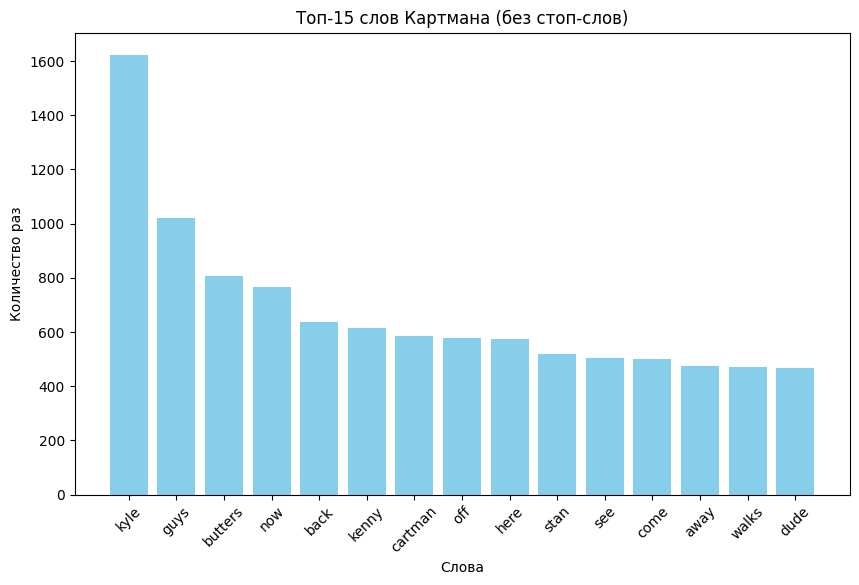

In [40]:
import matplotlib.pyplot as plt

top_words = dict(final_counts.most_common(15))
plt.figure(figsize=(10, 6))
plt.bar(top_words.keys(), top_words.values(), color='skyblue')
plt.title('Топ-15 слов Картмана (без стоп-слов)')
plt.xlabel('Слова')
plt.ylabel('Количество раз')
plt.xticks(rotation=45) # Поворачиваем подписи, чтобы они не наезжали друг на друга
plt.show()